# Notebook 22b — Wu 2003: SBI Training Dataset Generation for S-B3

## Purpose

This notebook mirrors notebook 22's role, but for the reduced-scope `S-B3` problem. `S-B3` keeps
the existing `S-B` instrumentation and plant model, but removes feed-fault scenarios from scope and
treats `z_A0_eff` as exogenous, fixed at nominal. The inference target is therefore the endogenous
4-vector `[alpha, beta_r, eta_col, xi_reb]`.

The notebook is structured around **two separate banks** so their downstream calibration behavior
can be compared directly:

1. a notebook-02-style **scenario-and-replicate** bank built from deterministic retained scenarios
2. a separate **mixed-wide-prior** bank built by sampling strict 4-D `S-B3` parameters continuously

**Prior history:** a full 4-D `BoxUniform` prior was tried first for bank 2 and abandoned -- individual
draws took up to ~2 minutes (uniform sampling frequently puts multiple parameters simultaneously near
their extreme bounds at once, which is hard for the ODE solver to converge on within the 4-hour
window). This mirrors the full 5-D system's own history (`cstr_sbi.recycle.priors.MixedWidePrior`
docstring): a full-uniform prior there was "aborted, accept rate collapsed to ~37%." The accepted fix
there -- widen only the parameters whose named-fault severities are poorly covered by the narrow
lognormal prior, keep the rest lognormal -- is what bank 2 now uses:
`alpha, beta_r ~ Uniform(low, high)`, `eta_col, xi_reb ~ truncated lognormal` (their existing narrow
marginals). See `cstr_sbi.recycle.sb3.mixed_wide_prior_4d_sb3` for the rationale and exact severity
numbers.

## Dataset specification

| Parameter | Value | Rationale |
|-----------|-------|-----------|
| Retained scenarios | 12 closed-loop (`S-B3`) | original no-feed subset only |
| Training rows | `N_TRAIN` | reduced-scope SBI bank |
| SBC screen set | `N_SBC_REDUCED` | cheap calibration screen |
| SBC confirm set | `N_SBC_CONFIRM` | higher-power calibration audit |
| Observation window | 4 hours | longer horizon to approach steady response |
| Time resolution | 1 minute (240 steps) | same historian rate, longer window |
| Observation structure | `S-B` summaries | no new instrumentation |
| Random seeds | fixed in code | reproducibility |

A 4-hour horizon is required, not just generous: `T_FINAL_H` was tested at 2 hours and
`W11_reactor_combined` failed the settling diagnostic (`max_rel_drift_sb=0.056` vs. the `0.05`
threshold) -- it genuinely needs the longer window to approach steady response.

## Simulation protocols

### Scenario-and-replicate branch

Each reduced-scope row is generated by:
1. selecting one retained `S-B3` closed-loop scenario from the reduced catalogue,
2. using that scenario's fixed endogenous 4-D truth `[alpha, beta_r, eta_col, xi_reb]`,
3. simulating the unchanged `S-B` plant for **4 hours** with 240 saved time steps,
4. adding 0.3% sensor noise to the full raw observation window,
5. computing the `S-B` summary vector from that noisy 4-hour window.

### Mixed-wide-prior branch

Later sections append a second set of cells that instead:
1. sample strict 4-D `S-B3` parameters from `mixed_wide_prior_4d_sb3()` (alpha, beta_r uniform;
   eta_col, xi_reb truncated lognormal),
2. simulate the unchanged `S-B` plant for **4 hours**,
3. add 0.3% sensor noise,
4. compute the same `S-B` summary vector.


## Output files

### Scenario-and-replicate outputs

- `data/wu2003_sbi_train_sb3_scenario_replicates_n{N_TRAIN}.npz`
- `results/24b_sysII_sb3_scenario_replicates_sbc_set_n{N_SBC_REDUCED}.npz`
- `results/24b_sysII_sb3_scenario_replicates_sbc_set_n{N_SBC_CONFIRM}.npz`

### Mixed-wide-prior outputs

- `data/wu2003_sbi_train_sb3_mixedwide_n{N_TRAIN}.npz`
- `results/24b_sysII_sb3_mixedwide_sbc_set_n{N_SBC_REDUCED}.npz`
- `results/24b_sysII_sb3_mixedwide_sbc_set_n{N_SBC_CONFIRM}.npz`

## Section 1 — Imports and setup

Loads the strict `S-B3` helpers and the same Wu2003 raw-window simulator used elsewhere. Unlike the
generic `_simulate_summary()` helper, this notebook defines its own reduced-scope summary generator
so the actual observation horizon can be increased from 2 hours to 4 hours.

### Detailed generation procedure

The generated banks in this notebook are **summary banks**, not a full archived observation dataset.
This section describes the **scenario-and-replicate branch**, which follows the notebook-02-style pipeline:

1. **Enumerate the retained `S-B3` scenario catalogue**
   The generator uses the 12 closed-loop `S-B3` scenarios only. Feed-fault scenarios remain out of scope.

2. **Use each scenario's fixed 4-D endogenous truth**
   For each retained scenario, the stored target is the strict 4-D vector
   `[alpha, beta_r, eta_col, xi_reb]`. Internally the simulator still appends nominal
   `z_A0_eff = 0.90` before calling the unchanged Wu2003 plant model.

3. **Reuse a cached nominal warm start**
   The notebook computes the nominal `S-B3` warm start once in the setup cell and reuses it for every
   retained scenario. This avoids recomputing a full steady-state solve inside the inner generation loop.

4. **Precompute one deterministic 4-hour raw observation window per retained scenario**
   As in notebook 02, the expensive plant simulation is separated from the replicate generation step.
   Each retained scenario is integrated once for 4 hours and saved at 1-minute resolution (`240` points).
   The 4-hour horizon is required: at 2 hours, `W11_reactor_combined` fails the settling diagnostic
   (`max_rel_drift_sb=0.056` vs. the `0.05` threshold) because it genuinely needs the longer window to
   approach steady response.

5. **Validate the deterministic scenario library before replication**
   Deterministic windows are checked for non-finite values and for the same drift / outlier diagnostics
   used previously. Only validated scenario windows are used as bases for noisy replicates.

6. **Generate repeated noisy replicates from the deterministic windows**
   Each saved row is produced by selecting a retained scenario in round-robin order and adding one
   independent Gaussian sensor-noise realization (`0.3%`) to that scenario's deterministic window.

7. **Compute the `S-B` summary vector**
   The noisy 4-hour window is compressed into the standard `S-B` summary vector using
   `compute_summaries(...)`. The parameter target is 4-D, but the summary representation is the same
   hand-engineered `S-B` representation used elsewhere in this project.

8. **Resume only from matching scenario-branch checkpoints**
   The scenario branch reloads its own renamed final or partial files if they already exist, and now
   validates their stored `t_final_h`/`n_save` against the current setup-cell config before reusing
   them (so a bank generated at a different horizon is never silently mixed in).

9. **Checkpoint accepted rows during long runs**
   Accepted `(theta4, summary)` rows are checkpointed to `.partial.npz` files every
   `CHECKPOINT_EVERY` accepted samples. Restarting the notebook resumes from the matching scenario-branch
   checkpoint rather than recomputing rows already obtained.

10. **Run post-generation diagnostics on saved banks**
   After generation, the notebook scans the saved summary matrices for robust-norm outliers and
   resimulates a few flagged rows for inspection. This is a final quality screen before the banks are
   used for SBC or posterior training.

Later sections append a **mixed-wide-prior comparison branch** that samples `theta4` continuously
(`alpha, beta_r` uniform; `eta_col, xi_reb` lognormal) instead of from the fixed 12-scenario catalogue,
saving to a separate set of renamed files so the two calibration workflows remain distinct. Because
every row there draws a distinct `theta`, it needs one fresh ODE solve per row (no reuse of a shared
deterministic window), so it checkpoints and reports progress more frequently than the scenario branch.

In [1]:
import pathlib, sys, time, importlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
sys.path.insert(0, str(ROOT / 'src'))

import cstr_sbi.recycle.sb3 as sb3
sb3 = importlib.reload(sb3)
from cstr_sbi.recycle.sb3 import (
    PRIOR_HIGH_SB3_4D,
    PRIOR_LOW_SB3_4D,
    SB3_PARAM_NAMES,
    mixed_wide_prior_4d_sb3,
    deterministic_window_sb3,
    noisy_replicates_sb3,
    nominal_warm_start_sb3,
    theta4_to_theta5,
    list_closed_loop_sb3,
)
from cstr_sbi.recycle.summaries import N_SUMMARIES_SB, SB_CHANNELS, compute_summaries

DATA = ROOT / 'data'; DATA.mkdir(exist_ok=True)
RESULTS = ROOT / 'results'; RESULTS.mkdir(exist_ok=True)
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)
LOGS = ROOT / 'logs'; LOGS.mkdir(exist_ok=True)

NOISE_PCT = 0.003
N_TRAIN = 5000
N_SBC_REDUCED = 120
N_SBC_CONFIRM = 400
T_FINAL_H = 4.0
N_SAVE = 240
CHECKPOINT_EVERY = 100
PROGRESS_EVERY_ATTEMPTS = 25
STEADY_MAX_REL_DRIFT = 0.05
MAX_NORM_CHANNEL = 3.0
MAX_ABS_RAW_OBS = 3.0e7
PROGRESS_LOG_PATH = LOGS / 'notebook22b_progress.log'

# T_FINAL_H=4h is required, not just nice-to-have: tested cutting it to 2h and
# W11_reactor_combined then fails the settling diagnostic (max_rel_drift_sb=0.056
# vs. the 0.05 threshold) -- it genuinely needs the longer window to approach
# steady response.
#
# The mixed-wide-prior branch (Sections 6-8 below) samples a fresh theta per row,
# so every row needs its own ODE solve -- unlike the scenario-and-replicate
# branch, which solves each of the 12 retained scenarios once and reuses that
# window for all noisy replicates. A full 4-D BoxUniform prior was tried first
# and abandoned: draws frequently put multiple parameters simultaneously near
# their extreme bounds at once, which the ODE solver struggles to converge on
# (some draws took up to ~2 minutes) -- the same failure mode already documented
# for the full 5-D system in `cstr_sbi.recycle.priors.MixedWidePrior` ("aborted,
# accept rate collapsed to ~37%"). The fix adopted there -- widen only the
# parameters with a real fault-coverage gap, keep the rest lognormal -- is what
# `mixed_wide_prior_4d_sb3()` implements here: alpha, beta_r uniform (their named
# fault severities sit 3.2-3.7 log-sigma into the narrow lognormal's tail),
# eta_col, xi_reb keep their narrow lognormal marginals (their worst-case
# severities are a comparatively mild ~2.2 log-sigma).
RUN_MIXEDWIDE_BRANCH = True

# The mixed-wide branch checkpoints/reports more often than the scenario branch,
# since accepted-row arrival is uneven (a few slow draws can otherwise delay the
# next checkpoint for a long time).
MIXEDWIDE_CHECKPOINT_EVERY = 20
MIXEDWIDE_TIME_CHECKPOINT_S = 60
MIXEDWIDE_PROGRESS_EVERY_ATTEMPTS = 5

SCENARIO_TRAIN_PATH = DATA / f'wu2003_sbi_train_sb3_scenario_replicates_n{N_TRAIN}.npz'
SCENARIO_SBC_R_PATH = RESULTS / f'24b_sysII_sb3_scenario_replicates_sbc_set_n{N_SBC_REDUCED}.npz'
SCENARIO_SBC_C_PATH = RESULTS / f'24b_sysII_sb3_scenario_replicates_sbc_set_n{N_SBC_CONFIRM}.npz'
MIXEDWIDE_TRAIN_PATH = DATA / f'wu2003_sbi_train_sb3_mixedwide_n{N_TRAIN}.npz'
MIXEDWIDE_SBC_R_PATH = RESULTS / f'24b_sysII_sb3_mixedwide_sbc_set_n{N_SBC_REDUCED}.npz'
MIXEDWIDE_SBC_C_PATH = RESULTS / f'24b_sysII_sb3_mixedwide_sbc_set_n{N_SBC_CONFIRM}.npz'
SCENARIO_FR_FIG_PATH = FIGURES / 'nb22b_scenario_replicates_fr_norm_check.png'
SCENARIO_DIAG_FIG_PATH = FIGURES / 'nb22b_scenario_replicates_summary_norm_diagnostics.png'
MIXEDWIDE_THETA_FIG_PATH = FIGURES / 'nb22b_mixedwide_theta_ranges.png'
MIXEDWIDE_DIAG_FIG_PATH = FIGURES / 'nb22b_mixedwide_summary_norm_diagnostics.png'

scenarios = list_closed_loop_sb3()
y0_sb3 = nominal_warm_start_sb3()
SCENARIO_BRANCH_COMPLETE = False
OI = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']
print(f'N_TRAIN={N_TRAIN}, N_SBC_REDUCED={N_SBC_REDUCED}, N_SBC_CONFIRM={N_SBC_CONFIRM}')
print(f'T_FINAL_H={T_FINAL_H}, N_SAVE={N_SAVE}, retained scenarios={len(scenarios)}')
print(f'CHECKPOINT_EVERY={CHECKPOINT_EVERY}, PROGRESS_EVERY_ATTEMPTS={PROGRESS_EVERY_ATTEMPTS}')
print(f'RUN_MIXEDWIDE_BRANCH={RUN_MIXEDWIDE_BRANCH}')
print(f'MIXEDWIDE_CHECKPOINT_EVERY={MIXEDWIDE_CHECKPOINT_EVERY}, MIXEDWIDE_TIME_CHECKPOINT_S={MIXEDWIDE_TIME_CHECKPOINT_S}, '
      f'MIXEDWIDE_PROGRESS_EVERY_ATTEMPTS={MIXEDWIDE_PROGRESS_EVERY_ATTEMPTS}')
print(f'PROGRESS_LOG_PATH={PROGRESS_LOG_PATH.relative_to(ROOT)}')
print(f'SCENARIO_TRAIN_PATH={SCENARIO_TRAIN_PATH.relative_to(ROOT)}')
print(f'MIXEDWIDE_TRAIN_PATH={MIXEDWIDE_TRAIN_PATH.relative_to(ROOT)}')
print('Cached nominal S-B3 warm start for reuse in all generated windows.')

N_TRAIN=5000, N_SBC_REDUCED=120, N_SBC_CONFIRM=400
T_FINAL_H=4.0, N_SAVE=240, retained scenarios=12
CHECKPOINT_EVERY=100, PROGRESS_EVERY_ATTEMPTS=25
RUN_MIXEDWIDE_BRANCH=True
MIXEDWIDE_CHECKPOINT_EVERY=20, MIXEDWIDE_TIME_CHECKPOINT_S=60, MIXEDWIDE_PROGRESS_EVERY_ATTEMPTS=5
PROGRESS_LOG_PATH=logs/notebook22b_progress.log
SCENARIO_TRAIN_PATH=data/wu2003_sbi_train_sb3_scenario_replicates_n5000.npz
MIXEDWIDE_TRAIN_PATH=data/wu2003_sbi_train_sb3_mixedwide_n5000.npz
Cached nominal S-B3 warm start for reuse in all generated windows.


In [2]:
def bank_status(path):
    candidates = [path, path.with_suffix('.partial.npz')]
    rows = []
    for candidate in candidates:
        exists = candidate.exists()
        row = {
            'file': candidate.name,
            'exists': exists,
            'rows': None,
            'attempts': None,
        }
        if exists:
            data = np.load(candidate)
            row['rows'] = int(len(data['thetas4']))
            row['attempts'] = int(data['attempts']) if 'attempts' in data.files else int(len(data['thetas4']))
        rows.append(row)
    return rows

status_rows = []
for branch, path in [
    ('scenario_replicates', SCENARIO_TRAIN_PATH),
    ('mixedwide', MIXEDWIDE_TRAIN_PATH),
]:
    for row in bank_status(path):
        row['branch'] = branch
        status_rows.append(row)

status_df = pd.DataFrame(status_rows, columns=['branch', 'file', 'exists', 'rows', 'attempts'])
print('Current S-B3 training-bank status:')
print(status_df.to_string(index=False))

Current S-B3 training-bank status:
             branch                                                       file  exists   rows  attempts
scenario_replicates         wu2003_sbi_train_sb3_scenario_replicates_n5000.npz    True 5000.0    5000.0
scenario_replicates wu2003_sbi_train_sb3_scenario_replicates_n5000.partial.npz    True 5000.0    5000.0
          mixedwide                   wu2003_sbi_train_sb3_mixedwide_n5000.npz   False    NaN       NaN
          mixedwide           wu2003_sbi_train_sb3_mixedwide_n5000.partial.npz   False    NaN       NaN


## Section 2 — Generate reduced-scope summary banks: scenario-and-replicate branch

This is the computationally intensive cell for the notebook-02-style branch. It:
1. builds one deterministic 4-hour window for each retained `S-B3` scenario,
2. generates repeated noisy replicates from those deterministic windows,
3. compresses each replicate to the standard `S-B` summary vector.

This branch now saves only to the renamed `scenario_replicates` files, so it is cleanly separated
from the appended (currently skipped) `uniform_prior` comparison branch below.

During execution, this cell prints and appends progress to `logs/notebook22b_progress.log`:
- whether the renamed scenario-branch bank was resumed from its own checkpoint,
- the validated deterministic scenario library,
- a heartbeat every `PROGRESS_EVERY_ATTEMPTS` replicate rows,
- a checkpoint report every `CHECKPOINT_EVERY` accepted rows.

In [3]:
def simulate_summary_sb3(theta4, rng, noise_pct=NOISE_PCT, t_final_h=T_FINAL_H, n_save=N_SAVE):
    theta4 = np.asarray(theta4, dtype=np.float32)
    t_h, raw_obs = deterministic_window_sb3(theta4, y0=y0_sb3, t_final_h=t_final_h, n_save=n_save)
    raw_obs = np.asarray(raw_obs)
    noisy = noisy_replicates_sb3(raw_obs, n_replicates=1, rng=rng, noise_pct=noise_pct)[0]
    summary = compute_summaries(noisy, 'S-B', np.asarray(t_h))
    return np.asarray(t_h), raw_obs, noisy, summary


def window_diag(raw_obs):
    raw_obs = np.asarray(raw_obs)
    check_idx = [0, 1, 2, 5, 6, 7, 8, 9, 10]
    norm_idx = [7, 8, 9, 10]
    q_start = max(0, 3 * len(raw_obs) // 4)
    last_q = raw_obs[q_start:]
    final = raw_obs[-1]
    q_mean = last_q.mean(axis=0)
    denom = np.maximum(np.abs(q_mean), 1e-6)
    rel_drift = np.abs(final - q_mean) / denom
    return {
        'max_rel_drift_sb': float(np.max(rel_drift[check_idx])),
        'mean_rel_drift_sb': float(np.mean(rel_drift[check_idx])),
        'max_norm_channel': float(np.max(np.abs(raw_obs[:, norm_idx]))),
        'max_abs_raw': float(np.max(np.abs(raw_obs))),
    }


def is_acceptable_window(diag):
    return (
        diag['max_rel_drift_sb'] <= STEADY_MAX_REL_DRIFT
        and diag['max_norm_channel'] <= MAX_NORM_CHANNEL
        and diag['max_abs_raw'] <= MAX_ABS_RAW_OBS
    )


def _check_bank_horizon(data, candidate_name):
    """Guard against silently reusing a cached bank generated under a different
    T_FINAL_H/N_SAVE (e.g. a stale 4-hour/240-step bank after the horizon was cut
    to 2 hours/120 steps). Raises rather than mixing windows of different length
    into the same downstream dataset."""
    stored_t_final_h = float(data['t_final_h']) if 't_final_h' in data.files else None
    stored_n_save = int(data['n_save']) if 'n_save' in data.files else None
    mismatch = (
        (stored_t_final_h is not None and not np.isclose(stored_t_final_h, T_FINAL_H))
        or (stored_n_save is not None and stored_n_save != N_SAVE)
    )
    if mismatch:
        raise ValueError(
            f'{candidate_name} was generated with t_final_h={stored_t_final_h}, n_save={stored_n_save}, '
            f'which does not match the current T_FINAL_H={T_FINAL_H}, N_SAVE={N_SAVE}. '
            f'Delete or rename {candidate_name} (and its .partial.npz sibling) to regenerate at the new horizon.'
        )


def load_matching_bank(out_path, label, emit_progress):
    if out_path.exists():
        data = np.load(out_path)
        _check_bank_horizon(data, out_path.name)
        emit_progress(f'[{label}] loading existing final bank: {out_path.name}')
        return (
            list(np.asarray(data['thetas4'], dtype=np.float32)),
            list(np.asarray(data['summaries'], dtype=np.float32)),
            int(data['attempts']) if 'attempts' in data.files else len(data['thetas4']),
            int(data['reject_nonfinite']) if 'reject_nonfinite' in data.files else 0,
            int(data['reject_diag']) if 'reject_diag' in data.files else 0,
        )
    partial_path = out_path.with_suffix('.partial.npz')
    if partial_path.exists():
        data = np.load(partial_path)
        _check_bank_horizon(data, partial_path.name)
        theta_rows = list(np.asarray(data['thetas4'], dtype=np.float32))
        summary_rows = list(np.asarray(data['summaries'], dtype=np.float32))
        attempts = int(data['attempts']) if 'attempts' in data.files else len(theta_rows)
        reject_nonfinite = int(data['reject_nonfinite']) if 'reject_nonfinite' in data.files else 0
        reject_diag = int(data['reject_diag']) if 'reject_diag' in data.files else 0
        emit_progress(
            f'[{label}] resuming from partial: accepted={len(theta_rows)}/{out_path.name}, '
            f'attempts={attempts}, reject_nonfinite={reject_nonfinite}, reject_diag={reject_diag}'
        )
        return theta_rows, summary_rows, attempts, reject_nonfinite, reject_diag
    emit_progress(f'[{label}] starting from scratch for {out_path.name}')
    return [], [], 0, 0, 0


def build_scenario_library(label, emit_progress):
    library = []
    emit_progress(f'[{label}] building deterministic scenario library from {len(scenarios)} retained scenarios')
    for sc in scenarios:
        t_h, raw_obs = deterministic_window_sb3(sc, y0=y0_sb3, t_final_h=T_FINAL_H, n_save=N_SAVE)
        raw_obs = np.asarray(raw_obs)
        if not np.isfinite(raw_obs).all():
            raise ValueError(f'{sc.name} produced non-finite deterministic observations')
        diag = window_diag(raw_obs)
        if not is_acceptable_window(diag):
            raise ValueError(f'{sc.name} failed deterministic diagnostics: {diag}')
        library.append({
            'scenario': sc,
            'theta4': np.asarray(sc.theta()[:4], dtype=np.float32),
            't_h': np.asarray(t_h),
            'raw_obs': raw_obs,
            'diag': diag,
        })
        emit_progress(
            f'[{label}] library {sc.name}: theta4={np.round(np.asarray(sc.theta()[:4]), 3).tolist()} '
            f'max_rel_drift_sb={diag["max_rel_drift_sb"]:.3f}, max_norm_channel={diag["max_norm_channel"]:.3f}'
        )
    return library


def save_bank(out_path, theta_rows, summary_rows, seed, attempts, reject_nonfinite, reject_diag, note):
    theta_arr = np.asarray(theta_rows, dtype=np.float32)
    summary_arr = np.asarray(summary_rows, dtype=np.float32)
    assert summary_arr.shape[1] == N_SUMMARIES_SB
    np.savez(
        out_path,
        thetas4=theta_arr,
        summaries=summary_arr,
        seed=seed,
        structure='S-B3',
        t_final_h=T_FINAL_H,
        n_save=N_SAVE,
        attempts=attempts,
        reject_nonfinite=reject_nonfinite,
        reject_diag=reject_diag,
        note=note,
    )
    return theta_arr, summary_arr


def generate_scenario_replicate_bank(out_path, n_rows, seed, label, library):
    def emit_progress(message, reset=False):
        print(message, flush=True)
        mode = 'w' if reset else 'a'
        with PROGRESS_LOG_PATH.open(mode, encoding='utf-8') as fh:
            fh.write(message + '\n')

    if label == 'scenario_train':
        emit_progress(f'=== notebook22b progress started at {time.strftime("%Y-%m-%d %H:%M:%S")} ===', reset=True)

    theta_rows, summary_rows, attempts, reject_nonfinite, reject_diag = load_matching_bank(out_path, label, emit_progress)
    if len(theta_rows) >= n_rows:
        theta_arr = np.asarray(theta_rows[:n_rows], dtype=np.float32)
        summary_arr = np.asarray(summary_rows[:n_rows], dtype=np.float32)
        emit_progress(f'[{label}] existing bank already satisfies target rows: {theta_arr.shape[0]}/{n_rows}')
        return theta_arr, summary_arr

    partial_path = out_path.with_suffix('.partial.npz')
    emit_progress(f'[{label}] target={out_path.name} partial={partial_path.name} n_rows={n_rows} seed={seed}')
    t0 = time.time()

    def report_progress(tag):
        elapsed = time.time() - t0
        accepted = len(theta_rows)
        accept_frac = accepted / max(attempts, 1)
        accepted_per_min = accepted / max(elapsed / 60.0, 1e-9)
        attempts_per_min = attempts / max(elapsed / 60.0, 1e-9)
        emit_progress(
            f'[{label}] {tag}: accepted={accepted}/{n_rows}, attempts={attempts}, '
            f'accept_frac={accept_frac:.3f}, accepted_per_min={accepted_per_min:.2f}, '
            f'attempts_per_min={attempts_per_min:.2f}, reject_nonfinite={reject_nonfinite}, '
            f'reject_diag={reject_diag}, elapsed_min={elapsed / 60.0:.1f}'
        )

    while len(theta_rows) < n_rows:
        attempts += 1
        entry = library[len(theta_rows) % len(library)]
        noisy = noisy_replicates_sb3(entry['raw_obs'], n_replicates=1, rng=np.random.default_rng(seed + attempts), noise_pct=NOISE_PCT)[0]
        summary = compute_summaries(noisy, 'S-B', entry['t_h'])
        if not np.isfinite(noisy).all() or not np.isfinite(summary).all():
            reject_nonfinite += 1
            if attempts % PROGRESS_EVERY_ATTEMPTS == 0:
                report_progress('heartbeat')
            continue
        theta_rows.append(entry['theta4'].copy())
        summary_rows.append(np.asarray(summary, dtype=np.float32))
        if attempts % PROGRESS_EVERY_ATTEMPTS == 0:
            report_progress('heartbeat')
        if len(theta_rows) % CHECKPOINT_EVERY == 0 or len(theta_rows) == n_rows:
            np.savez(partial_path,
                     thetas4=np.asarray(theta_rows, dtype=np.float32),
                     summaries=np.asarray(summary_rows, dtype=np.float32),
                     attempts=attempts,
                     reject_nonfinite=reject_nonfinite,
                     reject_diag=reject_diag,
                     t_final_h=T_FINAL_H,
                     n_save=N_SAVE)
            report_progress('checkpoint')

    theta_arr, summary_arr = save_bank(
        out_path,
        theta_rows,
        summary_rows,
        seed,
        attempts,
        reject_nonfinite,
        reject_diag,
        'Notebook-02-style deterministic-scenario-plus-replicate summary bank',
    )
    emit_progress(f'[{label}] saved {out_path.name}: theta4={theta_arr.shape}, summaries={summary_arr.shape}')
    return theta_arr, summary_arr


def generate_mixedwide_bank(out_path, n_rows, seed, label, prior_mixedwide,
                            checkpoint_every=CHECKPOINT_EVERY, time_checkpoint_s=None,
                            progress_every_attempts=PROGRESS_EVERY_ATTEMPTS):
    def emit_progress(message, reset=False):
        print(message, flush=True)
        mode = 'a'
        if reset:
            mode = 'w'
        with PROGRESS_LOG_PATH.open(mode, encoding='utf-8') as fh:
            fh.write(message + '\n')

    theta_rows, summary_rows, attempts, reject_nonfinite, reject_diag = load_matching_bank(out_path, label, emit_progress)
    if len(theta_rows) >= n_rows:
        theta_arr = np.asarray(theta_rows[:n_rows], dtype=np.float32)
        summary_arr = np.asarray(summary_rows[:n_rows], dtype=np.float32)
        emit_progress(f'[{label}] existing bank already satisfies target rows: {theta_arr.shape[0]}/{n_rows}')
        return theta_arr, summary_arr

    partial_path = out_path.with_suffix('.partial.npz')
    emit_progress(f'[{label}] target={out_path.name} partial={partial_path.name} n_rows={n_rows} seed={seed}')
    rng = np.random.default_rng(seed)
    t0 = time.time()
    last_checkpoint_t = t0

    def report_progress(tag):
        elapsed = time.time() - t0
        accepted = len(theta_rows)
        accept_frac = accepted / max(attempts, 1)
        accepted_per_min = accepted / max(elapsed / 60.0, 1e-9)
        attempts_per_min = attempts / max(elapsed / 60.0, 1e-9)
        remaining = max(n_rows - accepted, 0)
        eta_min = remaining / max(accepted_per_min, 1e-9) if accepted > 0 else float('nan')
        emit_progress(
            f'[{label}] {tag}: accepted={accepted}/{n_rows}, attempts={attempts}, '
            f'accept_frac={accept_frac:.3f}, accepted_per_min={accepted_per_min:.2f}, '
            f'attempts_per_min={attempts_per_min:.2f}, reject_nonfinite={reject_nonfinite}, '
            f'reject_diag={reject_diag}, elapsed_min={elapsed / 60.0:.1f}, '
            f'ETA_remaining_min={eta_min:.1f}'
        )

    def checkpoint_now():
        np.savez(partial_path,
                 thetas4=np.asarray(theta_rows, dtype=np.float32),
                 summaries=np.asarray(summary_rows, dtype=np.float32),
                 attempts=attempts,
                 reject_nonfinite=reject_nonfinite,
                 reject_diag=reject_diag,
                 t_final_h=T_FINAL_H,
                 n_save=N_SAVE)
        report_progress('checkpoint')

    while len(theta_rows) < n_rows:
        attempts += 1
        theta4 = prior_mixedwide.sample((1,)).numpy()[0]
        _, raw_obs, noisy, summary = simulate_summary_sb3(theta4, rng)
        if not np.isfinite(raw_obs).all() or not np.isfinite(noisy).all() or not np.isfinite(summary).all():
            reject_nonfinite += 1
            if attempts % progress_every_attempts == 0:
                report_progress('heartbeat')
            continue
        diag = window_diag(raw_obs)
        if not is_acceptable_window(diag):
            reject_diag += 1
            if attempts % progress_every_attempts == 0:
                report_progress('heartbeat')
            continue
        theta_rows.append(np.asarray(theta4, dtype=np.float32))
        summary_rows.append(np.asarray(summary, dtype=np.float32))
        if attempts % progress_every_attempts == 0:
            report_progress('heartbeat')
        due_by_count = len(theta_rows) % checkpoint_every == 0 or len(theta_rows) == n_rows
        due_by_time = time_checkpoint_s is not None and (time.time() - last_checkpoint_t) >= time_checkpoint_s
        if due_by_count or due_by_time:
            checkpoint_now()
            last_checkpoint_t = time.time()

    theta_arr, summary_arr = save_bank(
        out_path,
        theta_rows,
        summary_rows,
        seed,
        attempts,
        reject_nonfinite,
        reject_diag,
        'Mixed-wide-prior S-B3 summary bank (alpha, beta_r uniform; eta_col, xi_reb lognormal)',
    )
    emit_progress(f'[{label}] saved {out_path.name}: theta4={theta_arr.shape}, summaries={summary_arr.shape}')
    return theta_arr, summary_arr


def scenario_catalogue_membership_ok(theta_arr):
    catalogue = {tuple(np.round(np.asarray(sc.theta()[:4], dtype=np.float32), 6)) for sc in scenarios}
    return all(tuple(np.round(row, 6)) in catalogue for row in np.asarray(theta_arr, dtype=np.float32))


scenario_library = build_scenario_library('scenario_library', lambda message, reset=False: print(message, flush=True))
train_path = SCENARIO_TRAIN_PATH
sbc_r_path = SCENARIO_SBC_R_PATH
sbc_c_path = SCENARIO_SBC_C_PATH

theta_train, summary_train = generate_scenario_replicate_bank(train_path, N_TRAIN, seed=220010, label='scenario_train', library=scenario_library)
theta_sbc_r, summary_sbc_r = generate_scenario_replicate_bank(sbc_r_path, N_SBC_REDUCED, seed=220020, label='scenario_sbc_reduced', library=scenario_library)
theta_sbc_c, summary_sbc_c = generate_scenario_replicate_bank(sbc_c_path, N_SBC_CONFIRM, seed=220030, label='scenario_sbc_confirm', library=scenario_library)

[scenario_library] building deterministic scenario library from 12 retained scenarios


[scenario_library] library W1_healthy: theta4=[1.0, 1.0, 1.0, 1.0] max_rel_drift_sb=0.000, max_norm_channel=1.005


[scenario_library] library W2_cat_mild: theta4=[0.8500000238418579, 1.0, 1.0, 1.0] max_rel_drift_sb=0.022, max_norm_channel=1.028


[scenario_library] library W3_cat_severe: theta4=[0.6499999761581421, 1.0, 1.0, 1.0] max_rel_drift_sb=0.013, max_norm_channel=1.059


[scenario_library] library W4_cat_threshold: theta4=[0.550000011920929, 1.0, 1.0, 1.0] max_rel_drift_sb=0.017, max_norm_channel=1.076


[scenario_library] library W5_jacket_mild: theta4=[1.0, 0.800000011920929, 1.0, 1.0] max_rel_drift_sb=0.000, max_norm_channel=1.005


... (10 outputs left out)

[scenario_sbc_reduced] loading existing final bank: 24b_sysII_sb3_scenario_replicates_sbc_set_n120.npz


[scenario_sbc_reduced] existing bank already satisfies target rows: 120/120


[scenario_sbc_confirm] loading existing final bank: 24b_sysII_sb3_scenario_replicates_sbc_set_n400.npz


[scenario_sbc_confirm] existing bank already satisfies target rows: 400/400


## Section 3 — Dataset shapes, NaN checks, and physical-effect sanity check

As in notebook 22, the first validation step is structural: confirm the expected row counts and the
absence of NaN values. Then do a quick physical-effect check on `F_R_norm` over the retained `S-B3`
scenario catalogue to confirm the generated 4-hour windows still show meaningful differentiation.

=== Scenario-and-replicate bank shapes ===
  theta_train   : (5000, 4)
  summary_train : (5000, 66)
  theta_sbc_r   : (120, 4)
  summary_sbc_r : (120, 66)
  theta_sbc_c   : (400, 4)
  summary_sbc_c : (400, 66)

=== NaN / finite checks ===
  train summaries finite   : True
  reduced SBC finite       : True
  confirm SBC finite       : True

=== Parameter ranges (4-D endogenous scope) ===
  alpha   : train [0.550, 1.000]
  beta_r  : train [0.600, 1.000]
  eta_col : train [0.800, 1.000]
  xi_reb  : train [0.700, 1.000]


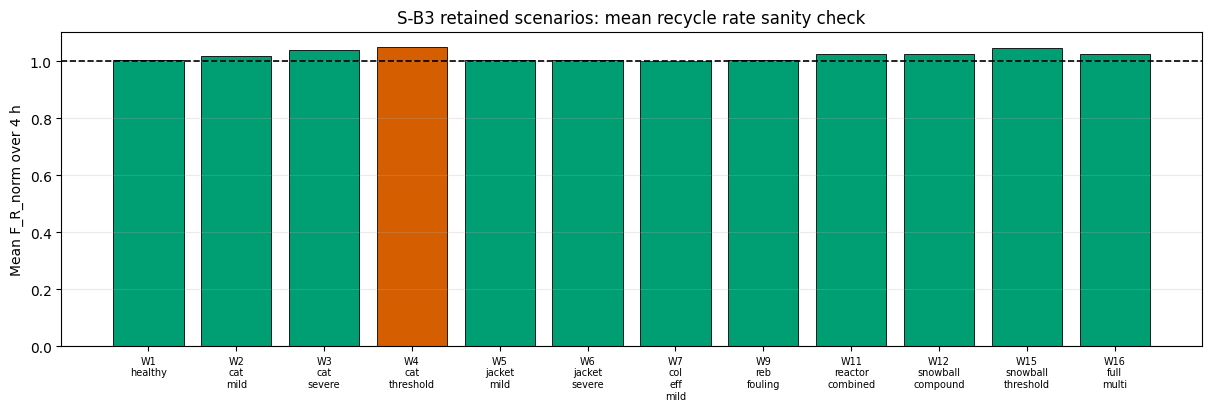

Saved nb22b_scenario_replicates_fr_norm_check.png


In [4]:
print('=== Scenario-and-replicate bank shapes ===')
print('  theta_train   :', theta_train.shape)
print('  summary_train :', summary_train.shape)
print('  theta_sbc_r   :', theta_sbc_r.shape)
print('  summary_sbc_r :', summary_sbc_r.shape)
print('  theta_sbc_c   :', theta_sbc_c.shape)
print('  summary_sbc_c :', summary_sbc_c.shape)
print()
print('=== NaN / finite checks ===')
print('  train summaries finite   :', bool(np.isfinite(summary_train).all()))
print('  reduced SBC finite       :', bool(np.isfinite(summary_sbc_r).all()))
print('  confirm SBC finite       :', bool(np.isfinite(summary_sbc_c).all()))
print()
print('=== Parameter ranges (4-D endogenous scope) ===')
for idx, name in enumerate(SB3_PARAM_NAMES):
    print(f'  {name:8s}: train [{theta_train[:, idx].min():.3f}, {theta_train[:, idx].max():.3f}]')

FR_IDX_RAW = 7
fr_rows = []
for sc in scenarios:
    t_h, raw_obs = deterministic_window_sb3(sc, y0=y0_sb3, t_final_h=T_FINAL_H, n_save=N_SAVE)
    raw_obs = np.asarray(raw_obs)
    fr_rows.append({'scenario': sc.name, 'mean_fr_norm': float(raw_obs[:, FR_IDX_RAW].mean())})
fr_df = pd.DataFrame(fr_rows)

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
colors = [OI[3] if fr < 1.05 else OI[6] if fr < 1.15 else OI[7] for fr in fr_df['mean_fr_norm']]
ax.bar(range(len(fr_df)), fr_df['mean_fr_norm'], color=colors, edgecolor='k', linewidth=0.6)
ax.axhline(1.0, color=OI[0], ls='--', lw=1.2)
ax.set_xticks(range(len(fr_df)))
ax.set_xticklabels([name.replace('_', '\n') for name in fr_df['scenario']], fontsize=7)
ax.set_ylabel(f'Mean F_R_norm over {T_FINAL_H:g} h')
ax.set_title('S-B3 retained scenarios: mean recycle rate sanity check')
ax.grid(True, axis='y', alpha=0.25)
plt.savefig(SCENARIO_FR_FIG_PATH, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved {SCENARIO_FR_FIG_PATH.name}')

## Section 4 — Diagnostics for suspicious generated samples

Before the round-trip/save check, run a targeted diagnostics pass on the generated summary banks to
catch samples that are finite but still look operationally suspicious: unusually large summary norms,
poor end-of-window settling, or extreme normalized-channel magnitudes. The purpose is to surface and
exclude near-divergent windows before they pollute downstream SBI calibration and classification.

=== Diagnostics: scenario_train ===
  rows=5000  flagged_by_summary_norm=0
  summary_norm median=57.276  p99=57.911  max=58.264
  no summary-norm outliers beyond robust z-threshold
=== Diagnostics: scenario_sbc_reduced ===
  rows=120  flagged_by_summary_norm=0
  summary_norm median=57.217  p99=57.906  max=57.908
  no summary-norm outliers beyond robust z-threshold
=== Diagnostics: scenario_sbc_confirm ===
  rows=400  flagged_by_summary_norm=0
  summary_norm median=57.274  p99=57.909  max=58.179
  no summary-norm outliers beyond robust z-threshold


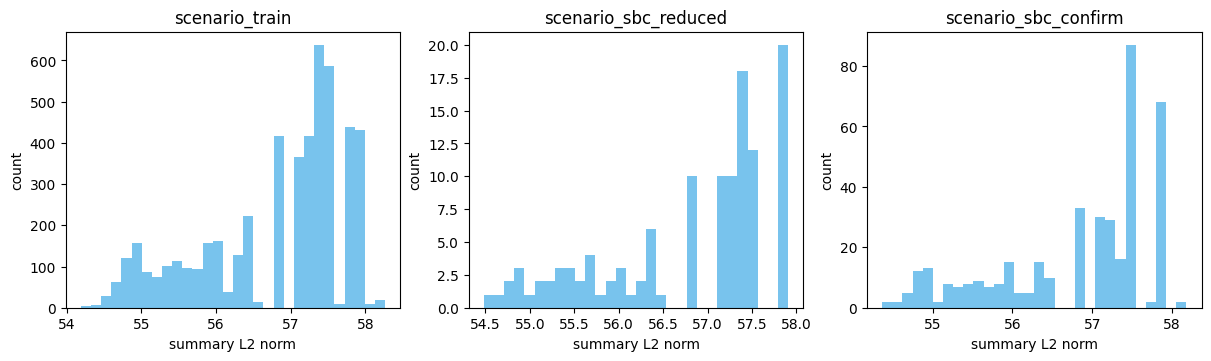

Saved nb22b_scenario_replicates_summary_norm_diagnostics.png


In [5]:
def robust_flag_summary_rows(summary_arr, z_thresh=6.0):
    norms = np.linalg.norm(summary_arr, axis=1)
    med = float(np.median(norms))
    mad = float(np.median(np.abs(norms - med)))
    if mad < 1e-12:
        z = np.zeros_like(norms)
    else:
        z = 0.6745 * (norms - med) / mad
    flagged = np.where(np.abs(z) > z_thresh)[0]
    return norms, z, flagged


def diagnose_bank(theta_arr, summary_arr, label, n_show=5):
    norms, robust_z, flagged = robust_flag_summary_rows(summary_arr)
    print(f'=== Diagnostics: {label} ===')
    print(f'  rows={len(theta_arr)}  flagged_by_summary_norm={len(flagged)}')
    print(f'  summary_norm median={np.median(norms):.3f}  p99={np.percentile(norms, 99):.3f}  max={np.max(norms):.3f}')
    flagged_rows = []
    for idx in flagged[:n_show]:
        rng = np.random.default_rng(900000 + int(idx))
        t_h, raw_obs, noisy, summary = simulate_summary_sb3(theta_arr[idx], rng)
        diag = window_diag(raw_obs)
        flagged_rows.append({
            'idx': int(idx),
            'summary_norm': float(norms[idx]),
            'robust_z': float(robust_z[idx]),
            'max_rel_drift_sb': diag['max_rel_drift_sb'],
            'max_norm_channel': diag['max_norm_channel'],
            'max_abs_raw': diag['max_abs_raw'],
            'theta4': np.round(theta_arr[idx], 4).tolist(),
        })
    diag_df = pd.DataFrame(flagged_rows)
    if len(diag_df) > 0:
        print(diag_df.to_string(index=False))
    else:
        print('  no summary-norm outliers beyond robust z-threshold')
    return {'norms': norms, 'robust_z': robust_z, 'flagged': flagged, 'details': diag_df}

train_diag = diagnose_bank(theta_train, summary_train, 'scenario_train')
sbc_r_diag = diagnose_bank(theta_sbc_r, summary_sbc_r, 'scenario_sbc_reduced')
sbc_c_diag = diagnose_bank(theta_sbc_c, summary_sbc_c, 'scenario_sbc_confirm')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, title, diag in zip(axes, ['scenario_train', 'scenario_sbc_reduced', 'scenario_sbc_confirm'], [train_diag, sbc_r_diag, sbc_c_diag]):
    ax.hist(diag['norms'], bins=30, color=OI[2], alpha=0.8)
    ax.set_title(title)
    ax.set_xlabel('summary L2 norm')
    ax.set_ylabel('count')
plt.savefig(SCENARIO_DIAG_FIG_PATH, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved {SCENARIO_DIAG_FIG_PATH.name}')

### Results commentary: scenario-and-replicate generation and diagnostics

The renamed scenario-and-replicate bank should still show the same broad physics as the original
data-generation notebook: reactor-side and column-side degradations perturb recycle flow in different
magnitudes, while all stored summary rows remain finite and structurally consistent.

The diagnostics section above is intentionally conservative: it tries to catch windows that are
finite but operationally suspicious, such as poor late-window settling or unusually large summary
norms. A clean pass here is stronger evidence that the saved banks will not create avoidable trouble
for SBC or downstream classification.

## Section 5 — Save / load round-trip verification

The three saved `.npz` files are the actual interface to downstream training. A simple round-trip load
check ensures the files were written with the expected shapes and can be reloaded without silent
shape drift or corruption.

## Final acceptance criteria for the scenario-and-replicate branch

This branch passes if:
1. all three datasets are generated with the requested row counts,
2. all summary vectors are finite and have the expected `S-B` dimension,
3. the stored 4-D parameter rows belong to the retained `S-B3` scenario catalogue,
4. the retained 4-hour windows show nontrivial recycle-flow differentiation across scenarios,
5. no bank has more than 1% robust summary-norm outliers on the diagnostics pass.

In [6]:
train_rt = np.load(train_path)
sbc_r_rt = np.load(sbc_r_path)
sbc_c_rt = np.load(sbc_c_path)
print('=== Scenario-and-replicate round-trip verification ===')
print('  train   :', train_rt['thetas4'].shape, train_rt['summaries'].shape)
print('  sbc_r   :', sbc_r_rt['thetas4'].shape, sbc_r_rt['summaries'].shape)
print('  sbc_c   :', sbc_c_rt['thetas4'].shape, sbc_c_rt['summaries'].shape)

criteria = [
    ('training row count', theta_train.shape[0] == N_TRAIN, f"{theta_train.shape[0]} vs {N_TRAIN}"),
    ('reduced SBC row count', theta_sbc_r.shape[0] == N_SBC_REDUCED, f"{theta_sbc_r.shape[0]} vs {N_SBC_REDUCED}"),
    ('confirm SBC row count', theta_sbc_c.shape[0] == N_SBC_CONFIRM, f"{theta_sbc_c.shape[0]} vs {N_SBC_CONFIRM}"),
    ('all summaries finite', bool(np.isfinite(np.vstack([summary_train, summary_sbc_r, summary_sbc_c])).all()), 'finite check'),
    ('summary dimension is S-B', summary_train.shape[1] == N_SUMMARIES_SB, str(summary_train.shape[1])),
    ('rows belong to retained scenario catalogue', scenario_catalogue_membership_ok(theta_train), 'catalogue membership check'),
    ('recycle flow differentiates retained scenarios', float(fr_df['mean_fr_norm'].std()) > 0.0, f"std={fr_df['mean_fr_norm'].std():.4f}"),
    ('train summary-norm outliers <= 1%', len(train_diag['flagged']) <= max(1, int(0.01 * len(theta_train))), f"{len(train_diag['flagged'])}/{len(theta_train)}"),
    ('reduced SBC summary-norm outliers <= 1%', len(sbc_r_diag['flagged']) <= max(1, int(0.01 * len(theta_sbc_r))), f"{len(sbc_r_diag['flagged'])}/{len(theta_sbc_r)}"),
    ('confirm SBC summary-norm outliers <= 1%', len(sbc_c_diag['flagged']) <= max(1, int(0.01 * len(theta_sbc_c))), f"{len(sbc_c_diag['flagged'])}/{len(theta_sbc_c)}"),
]
for name, passed, value in criteria:
    print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")

SCENARIO_BRANCH_COMPLETE = all(passed for _, passed, _ in criteria)
print(f'SCENARIO_BRANCH_COMPLETE={SCENARIO_BRANCH_COMPLETE}')

=== Scenario-and-replicate round-trip verification ===
  train   : (5000, 4) (5000, 66)
  sbc_r   : (120, 4) (120, 66)
  sbc_c   : (400, 4) (400, 66)
PASS | training row count: 5000 vs 5000
PASS | reduced SBC row count: 120 vs 120
PASS | confirm SBC row count: 400 vs 400
PASS | all summaries finite: finite check
PASS | summary dimension is S-B: 66
PASS | rows belong to retained scenario catalogue: catalogue membership check
PASS | recycle flow differentiates retained scenarios: std=0.0180
PASS | train summary-norm outliers <= 1%: 0/5000
PASS | reduced SBC summary-norm outliers <= 1%: 0/120
PASS | confirm SBC summary-norm outliers <= 1%: 0/400
SCENARIO_BRANCH_COMPLETE=True


## Section 6 — Generate comparison banks from a mixed-wide prior

This appended branch recreates the older prior-sampling idea, but now with `mixed_wide_prior_4d_sb3()`
over `S-B3` (`alpha, beta_r ~ Uniform`; `eta_col, xi_reb ~` their existing narrow truncated-lognormal
marginals) and with completely separate output files. These banks are intended for side-by-side
calibration comparison against the scenario-and-replicate branch above.

The simulator, observation horizon, summary map, diagnostics gate, and checkpointing rules remain
the same. The only difference is how `theta4` is chosen: here it is sampled from the mixed-wide
prior instead of being drawn from the retained scenario catalogue.

A full 4-D `BoxUniform` prior was tried here first and abandoned: individual draws took up to ~2
minutes because uniform sampling frequently puts *all four* parameters simultaneously near their
extreme bounds at once, which the ODE solver struggles to converge on within the 4-hour window. This
is the same failure mode already documented for the full 5-D system
(`cstr_sbi.recycle.priors.MixedWidePrior` docstring: "a full 5-D uniform prior was already tried and
aborted, accept rate collapsed to ~37%"). Widening only `alpha, beta_r` -- the two parameters whose
named-fault severities are worst-covered by the narrow lognormal prior -- keeps `eta_col, xi_reb`
well-behaved and should substantially reduce how often multiple parameters go extreme at once.

In [7]:
if not RUN_MIXEDWIDE_BRANCH:
    print('=== mixed-wide-prior branch skipped (RUN_MIXEDWIDE_BRANCH=False) ===', flush=True)
    print('Proceeding with the scenario-and-replicate bank only for now.', flush=True)
    theta_train_mixedwide = summary_train_mixedwide = None
    theta_sbc_r_mixedwide = summary_sbc_r_mixedwide = None
    theta_sbc_c_mixedwide = summary_sbc_c_mixedwide = None
else:
    if not SCENARIO_BRANCH_COMPLETE:
        raise RuntimeError('Scenario-and-replicate branch must finish successfully before mixed-wide-prior generation starts.')

    with PROGRESS_LOG_PATH.open('a', encoding='utf-8') as fh:
        fh.write('=== scenario branch complete; starting mixed-wide-prior branch ===\n')
    print('=== scenario branch complete; starting mixed-wide-prior branch ===', flush=True)

    prior_mixedwide_4d = mixed_wide_prior_4d_sb3()
    mixedwide_train_path = MIXEDWIDE_TRAIN_PATH
    mixedwide_sbc_r_path = MIXEDWIDE_SBC_R_PATH
    mixedwide_sbc_c_path = MIXEDWIDE_SBC_C_PATH

    theta_train_mixedwide, summary_train_mixedwide = generate_mixedwide_bank(
        mixedwide_train_path, N_TRAIN, seed=221010, label='mixedwide_train', prior_mixedwide=prior_mixedwide_4d,
        checkpoint_every=MIXEDWIDE_CHECKPOINT_EVERY, time_checkpoint_s=MIXEDWIDE_TIME_CHECKPOINT_S,
        progress_every_attempts=MIXEDWIDE_PROGRESS_EVERY_ATTEMPTS,
     )
    theta_sbc_r_mixedwide, summary_sbc_r_mixedwide = generate_mixedwide_bank(
        mixedwide_sbc_r_path, N_SBC_REDUCED, seed=221020, label='mixedwide_sbc_reduced', prior_mixedwide=prior_mixedwide_4d,
        checkpoint_every=MIXEDWIDE_CHECKPOINT_EVERY, time_checkpoint_s=MIXEDWIDE_TIME_CHECKPOINT_S,
        progress_every_attempts=MIXEDWIDE_PROGRESS_EVERY_ATTEMPTS,
     )
    theta_sbc_c_mixedwide, summary_sbc_c_mixedwide = generate_mixedwide_bank(
        mixedwide_sbc_c_path, N_SBC_CONFIRM, seed=221030, label='mixedwide_sbc_confirm', prior_mixedwide=prior_mixedwide_4d,
        checkpoint_every=MIXEDWIDE_CHECKPOINT_EVERY, time_checkpoint_s=MIXEDWIDE_TIME_CHECKPOINT_S,
        progress_every_attempts=MIXEDWIDE_PROGRESS_EVERY_ATTEMPTS,
     )

=== scenario branch complete; starting mixed-wide-prior branch ===


[mixedwide_train] starting from scratch for wu2003_sbi_train_sb3_mixedwide_n5000.npz


[mixedwide_train] target=wu2003_sbi_train_sb3_mixedwide_n5000.npz partial=wu2003_sbi_train_sb3_mixedwide_n5000.partial.npz n_rows=5000 seed=221010


[mixedwide_train] heartbeat: accepted=5/5000, attempts=5, accept_frac=1.000, accepted_per_min=234.79, attempts_per_min=234.79, reject_nonfinite=0, reject_diag=0, elapsed_min=0.0, ETA_remaining_min=21.3


[mixedwide_train] heartbeat: accepted=10/5000, attempts=10, accept_frac=1.000, accepted_per_min=227.93, attempts_per_min=227.93, reject_nonfinite=0, reject_diag=0, elapsed_min=0.0, ETA_remaining_min=21.9


[mixedwide_train] heartbeat: accepted=15/5000, attempts=15, accept_frac=1.000, accepted_per_min=19.08, attempts_per_min=19.08, reject_nonfinite=0, reject_diag=0, elapsed_min=0.8, ETA_remaining_min=261.2


... (1,622 outputs left out)

[mixedwide_sbc_confirm] heartbeat: accepted=396/400, attempts=400, accept_frac=0.990, accepted_per_min=4.10, attempts_per_min=4.15, reject_nonfinite=4, reject_diag=0, elapsed_min=96.5, ETA_remaining_min=1.0


[mixedwide_sbc_confirm] checkpoint: accepted=398/400, attempts=402, accept_frac=0.990, accepted_per_min=4.09, attempts_per_min=4.13, reject_nonfinite=4, reject_diag=0, elapsed_min=97.4, ETA_remaining_min=0.5


[mixedwide_sbc_confirm] checkpoint: accepted=400/400, attempts=404, accept_frac=0.990, accepted_per_min=4.10, attempts_per_min=4.14, reject_nonfinite=4, reject_diag=0, elapsed_min=97.6, ETA_remaining_min=0.0


[mixedwide_sbc_confirm] saved 24b_sysII_sb3_mixedwide_sbc_set_n400.npz: theta4=(400, 4), summaries=(400, 66)


## Section 7 — Mixed-wide-prior shapes and support checks

This section mirrors the structural checks above, but for the separate mixed-wide-prior banks. In place
of scenario-catalogue membership, it verifies that the sampled parameter rows stay within the strict
4-D `S-B3` box and that all four marginals are visibly populated (two uniform, two lognormal).

=== Mixed-wide-prior bank shapes ===
  theta_train_mixedwide   : (5000, 4)
  summary_train_mixedwide : (5000, 66)
  theta_sbc_r_mixedwide   : (120, 4)
  summary_sbc_r_mixedwide : (120, 66)
  theta_sbc_c_mixedwide   : (400, 4)
  summary_sbc_c_mixedwide : (400, 66)

=== NaN / finite checks ===
  train summaries finite   : True
  reduced SBC finite       : True
  confirm SBC finite       : True

=== Parameter ranges against the S-B3 box ===
  alpha    (uniform  ): train [0.400, 1.200] within [0.400, 1.200]
  beta_r   (uniform  ): train [0.400, 1.200] within [0.400, 1.200]
  eta_col  (lognormal): train [0.719, 1.000] within [0.500, 1.000]
  xi_reb   (lognormal): train [0.561, 1.200] within [0.400, 1.200]


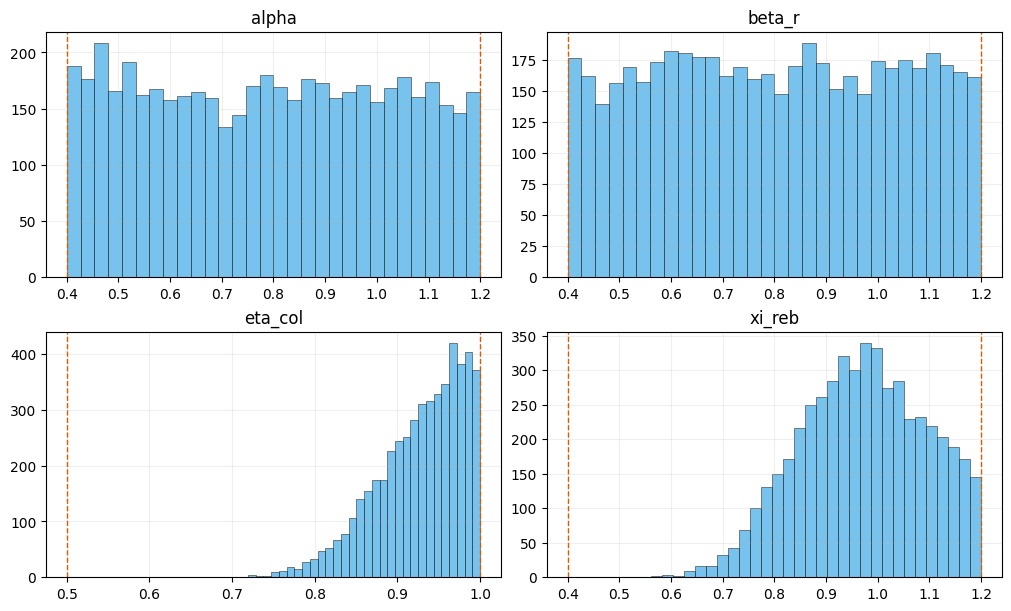

Saved nb22b_mixedwide_theta_ranges.png


In [8]:
if not RUN_MIXEDWIDE_BRANCH:
    print('=== mixed-wide-prior shapes/support checks skipped (RUN_MIXEDWIDE_BRANCH=False) ===', flush=True)
else:
    print('=== Mixed-wide-prior bank shapes ===')
    print('  theta_train_mixedwide   :', theta_train_mixedwide.shape)
    print('  summary_train_mixedwide :', summary_train_mixedwide.shape)
    print('  theta_sbc_r_mixedwide   :', theta_sbc_r_mixedwide.shape)
    print('  summary_sbc_r_mixedwide :', summary_sbc_r_mixedwide.shape)
    print('  theta_sbc_c_mixedwide   :', theta_sbc_c_mixedwide.shape)
    print('  summary_sbc_c_mixedwide :', summary_sbc_c_mixedwide.shape)
    print()
    print('=== NaN / finite checks ===')
    print('  train summaries finite   :', bool(np.isfinite(summary_train_mixedwide).all()))
    print('  reduced SBC finite       :', bool(np.isfinite(summary_sbc_r_mixedwide).all()))
    print('  confirm SBC finite       :', bool(np.isfinite(summary_sbc_c_mixedwide).all()))
    print()
    print('=== Parameter ranges against the S-B3 box ===')
    for idx, name in enumerate(SB3_PARAM_NAMES):
        kind = 'uniform' if idx in (0, 1) else 'lognormal'
        print(
            f'  {name:8s} ({kind:9s}): train [{theta_train_mixedwide[:, idx].min():.3f}, {theta_train_mixedwide[:, idx].max():.3f}] '
            f'within [{PRIOR_LOW_SB3_4D[idx]:.3f}, {PRIOR_HIGH_SB3_4D[idx]:.3f}]'
        )

    fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
    for ax, idx, name in zip(axes.ravel(), range(4), SB3_PARAM_NAMES):
        ax.hist(theta_train_mixedwide[:, idx], bins=30, color=OI[2], alpha=0.8, edgecolor='k', linewidth=0.4)
        ax.axvline(PRIOR_LOW_SB3_4D[idx], color=OI[6], ls='--', lw=1.0)
        ax.axvline(PRIOR_HIGH_SB3_4D[idx], color=OI[6], ls='--', lw=1.0)
        ax.set_title(name)
        ax.grid(True, alpha=0.2)
    plt.savefig(MIXEDWIDE_THETA_FIG_PATH, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved {MIXEDWIDE_THETA_FIG_PATH.name}')

## Section 8 — Mixed-wide-prior diagnostics and round-trip verification

This final appended branch mirrors the summary-norm diagnostics and round-trip load check used above,
but applies them to the separately saved mixed-wide-prior banks. The goal is to keep the two
training-bank recipes directly comparable while preserving independent saved artifacts.

=== Diagnostics: mixedwide_train ===
  rows=5000  flagged_by_summary_norm=0
  summary_norm median=57.367  p99=58.342  max=58.801
  no summary-norm outliers beyond robust z-threshold
=== Diagnostics: mixedwide_sbc_reduced ===
  rows=120  flagged_by_summary_norm=0
  summary_norm median=57.378  p99=58.274  max=58.302
  no summary-norm outliers beyond robust z-threshold
=== Diagnostics: mixedwide_sbc_confirm ===
  rows=400  flagged_by_summary_norm=0
  summary_norm median=57.312  p99=58.308  max=58.495
  no summary-norm outliers beyond robust z-threshold


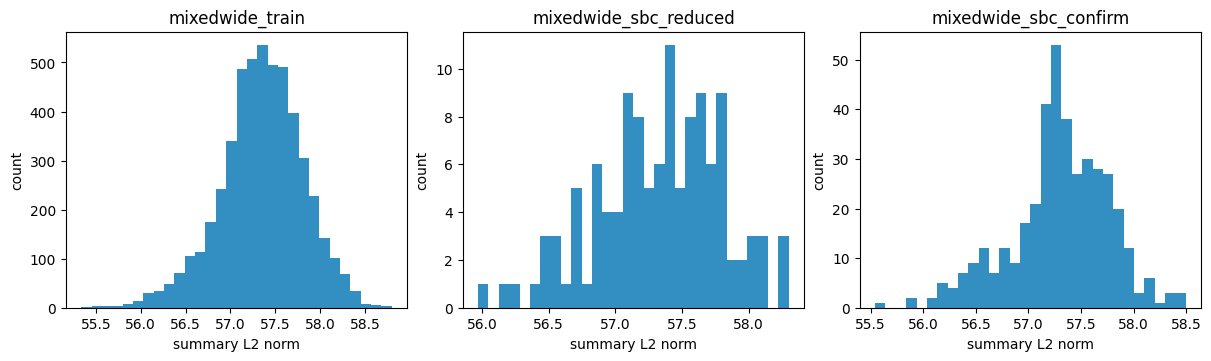

Saved nb22b_mixedwide_summary_norm_diagnostics.png
=== Mixed-wide-prior round-trip verification ===
  train   : (5000, 4) (5000, 66)
  sbc_r   : (120, 4) (120, 66)
  sbc_c   : (400, 4) (400, 66)
PASS | training row count: 5000 vs 5000
PASS | reduced SBC row count: 120 vs 120
PASS | confirm SBC row count: 400 vs 400
PASS | all summaries finite: finite check
PASS | summary dimension is S-B: 66
PASS | mixed-wide samples remain within strict support: support bounds check
PASS | mixed-wide branch has nonzero spread in every parameter: [0.23309999704360962, 0.2304999977350235, 0.05310000106692314, 0.121799997985363]
PASS | train summary-norm outliers <= 1%: 0/5000
PASS | reduced SBC summary-norm outliers <= 1%: 0/120
PASS | confirm SBC summary-norm outliers <= 1%: 0/400


In [9]:
if not RUN_MIXEDWIDE_BRANCH:
    print('=== mixed-wide-prior diagnostics/round-trip checks skipped (RUN_MIXEDWIDE_BRANCH=False) ===', flush=True)
else:
    train_diag_mixedwide = diagnose_bank(theta_train_mixedwide, summary_train_mixedwide, 'mixedwide_train')
    sbc_r_diag_mixedwide = diagnose_bank(theta_sbc_r_mixedwide, summary_sbc_r_mixedwide, 'mixedwide_sbc_reduced')
    sbc_c_diag_mixedwide = diagnose_bank(theta_sbc_c_mixedwide, summary_sbc_c_mixedwide, 'mixedwide_sbc_confirm')

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
    for ax, title, diag in zip(
        axes,
        ['mixedwide_train', 'mixedwide_sbc_reduced', 'mixedwide_sbc_confirm'],
        [train_diag_mixedwide, sbc_r_diag_mixedwide, sbc_c_diag_mixedwide],
    ):
        ax.hist(diag['norms'], bins=30, color=OI[5], alpha=0.8)
        ax.set_title(title)
        ax.set_xlabel('summary L2 norm')
        ax.set_ylabel('count')
    plt.savefig(MIXEDWIDE_DIAG_FIG_PATH, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved {MIXEDWIDE_DIAG_FIG_PATH.name}')

    mixedwide_train_rt = np.load(mixedwide_train_path)
    mixedwide_sbc_r_rt = np.load(mixedwide_sbc_r_path)
    mixedwide_sbc_c_rt = np.load(mixedwide_sbc_c_path)
    print('=== Mixed-wide-prior round-trip verification ===')
    print('  train   :', mixedwide_train_rt['thetas4'].shape, mixedwide_train_rt['summaries'].shape)
    print('  sbc_r   :', mixedwide_sbc_r_rt['thetas4'].shape, mixedwide_sbc_r_rt['summaries'].shape)
    print('  sbc_c   :', mixedwide_sbc_c_rt['thetas4'].shape, mixedwide_sbc_c_rt['summaries'].shape)

    mixedwide_within_support = bool((
        (theta_train_mixedwide >= PRIOR_LOW_SB3_4D).all()
        and (theta_train_mixedwide <= PRIOR_HIGH_SB3_4D).all()
    ))

    criteria_mixedwide = [
        ('training row count', theta_train_mixedwide.shape[0] == N_TRAIN, f"{theta_train_mixedwide.shape[0]} vs {N_TRAIN}"),
        ('reduced SBC row count', theta_sbc_r_mixedwide.shape[0] == N_SBC_REDUCED, f"{theta_sbc_r_mixedwide.shape[0]} vs {N_SBC_REDUCED}"),
        ('confirm SBC row count', theta_sbc_c_mixedwide.shape[0] == N_SBC_CONFIRM, f"{theta_sbc_c_mixedwide.shape[0]} vs {N_SBC_CONFIRM}"),
        ('all summaries finite', bool(np.isfinite(np.vstack([summary_train_mixedwide, summary_sbc_r_mixedwide, summary_sbc_c_mixedwide])).all()), 'finite check'),
        ('summary dimension is S-B', summary_train_mixedwide.shape[1] == N_SUMMARIES_SB, str(summary_train_mixedwide.shape[1])),
        ('mixed-wide samples remain within strict support', mixedwide_within_support, 'support bounds check'),
        ('mixed-wide branch has nonzero spread in every parameter', bool((theta_train_mixedwide.std(axis=0) > 0).all()), np.round(theta_train_mixedwide.std(axis=0), 4).tolist()),
        ('train summary-norm outliers <= 1%', len(train_diag_mixedwide['flagged']) <= max(1, int(0.01 * len(theta_train_mixedwide))), f"{len(train_diag_mixedwide['flagged'])}/{len(theta_train_mixedwide)}"),
        ('reduced SBC summary-norm outliers <= 1%', len(sbc_r_diag_mixedwide['flagged']) <= max(1, int(0.01 * len(theta_sbc_r_mixedwide))), f"{len(sbc_r_diag_mixedwide['flagged'])}/{len(theta_sbc_r_mixedwide)}"),
        ('confirm SBC summary-norm outliers <= 1%', len(sbc_c_diag_mixedwide['flagged']) <= max(1, int(0.01 * len(theta_sbc_c_mixedwide))), f"{len(sbc_c_diag_mixedwide['flagged'])}/{len(theta_sbc_c_mixedwide)}"),
    ]
    for name, passed, value in criteria_mixedwide:
        print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")